Before starting: download the data from Moodle (files too large for GitHub) and place it so that it matches the structure below.
The Moodle archive names the anatomical folder `T1w/`: rename it to `T1/`.

```code
NSSP-Mini-project-1
    /Project_notebook.ipynb
    /data
        /T1
            /T1w.nii.gz
        /fMRI
            /tfMRI_LANGUAGE_LR
                /tfMRI_LANGUAGE_LR_task_onsets.csv
                /tfMRI_LANGUAGE_LR.nii.gz
        /derivatives          <- created by this notebook (outputs + figures)
```

Requirements: FSL (`bet`, `fast`, `flirt` in the PATH, `FSLDIR` set) and the Python packages `nilearn`, `nibabel`, `antspyx`.

In [1]:
import os
import os.path as op
import shutil
import subprocess
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from nilearn import plotting # brain image plotting

# Data folder, relative to this notebook: works on every machine without editing
data_dir = op.abspath("data")


out_dir = op.join(data_dir, "derivatives")
out_anatomical_dir = op.join(out_dir, "anat")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(out_anatomical_dir, exist_ok=True)

t1_path = op.join(data_dir, "T1", "T1w.nii.gz") # original structural image
fig_dir = op.join(out_dir, "figures") # folder for the saved figures
os.makedirs(fig_dir, exist_ok=True)                 # create output folders (no error if they exist)
FIG_DPI = 300                                       # enough for the PDF report (1000 dpi gave 9000 px images)


# FSL environment
## REQUIRES FSL download (https://fsl.fmrib.ox.ac.uk/fsl/docs/install/index.html)
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder (this is the default, change if needed)
os.environ["FSLDIR"] = fsldir                       # make sure FSL tools can find their files
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"            # FSL writes .nii.gz files
os.environ["PATH"] = os.pathsep.join([op.join(fsldir, "bin"), op.join(fsldir, "share", "fsl", "bin"), os.environ["PATH"]])

# MNI152 templates
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_2mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # skull-stripped template


assert op.exists(t1_path), f"T1w image not found: {t1_path}"
assert op.exists(out_anatomical_dir), f"Output directory not found: {out_anatomical_dir}"
assert op.exists(fig_dir), f"Output directory not found: {fig_dir}"
assert op.exists(mni_head), f"MNI template not found: {mni_head}"
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"
assert shutil.which("bet"), f"FSL tools not found in the PATH (FSLDIR={fsldir})"

print("All good. T1w:", t1_path)
print("FSL directory:", fsldir)

All good. T1w: /Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz
FSL directory: /Users/matt/fsl


## 1. skull-stripping with FSL BET

**Purpose.** Remove the skull, scalp and neck. Their intensities would bias the next steps: FAST models the voxel intensities as a mixture of tissues, and the registration maximises an intensity similarity with a skull-stripped template.

**Parameters.** `-R` (robust brain-centre estimation) and `-f 0.3`, which is more permissive than the default 0.5.

> **To decide as a group (review part1-review).** The annex below compares `-f 0.3` and `-f 0.5`.
> - 0.5 removes ~59 mL (1379 → 1322 mL), mostly at the base of the brain. FAST labels most of it as CSF/meninges (~47 mL) and ~11 mL as grey matter.
> - On the figure, 0.3 keeps small non-brain islands (orbit/sinus region at z = -30, sella turcica at x = 10).
> - 0.5 follows the cortex without visibly cutting the temporal poles or the cerebellum.
>
> Unless someone sees lost cortex on other slices, `-f 0.5` looks at least as good. Whichever value is chosen, the justification should be stated in the report.

In [2]:
brain_prefix = op.join(out_anatomical_dir, "T1w_brain") # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                        # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                    # binary brain mask

# FSL BET: -R robust centre estimation, -f 0.3 threshold (see justification above), -m save mask
subprocess.run(["bet", t1_path, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)

CompletedProcess(args=['bet', '/Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz', '/Users/matt/Desktop/NSSP-Mini-project-1/data/derivatives/anat/T1w_brain', '-R', '-f', '0.3', '-m'], returncode=0)

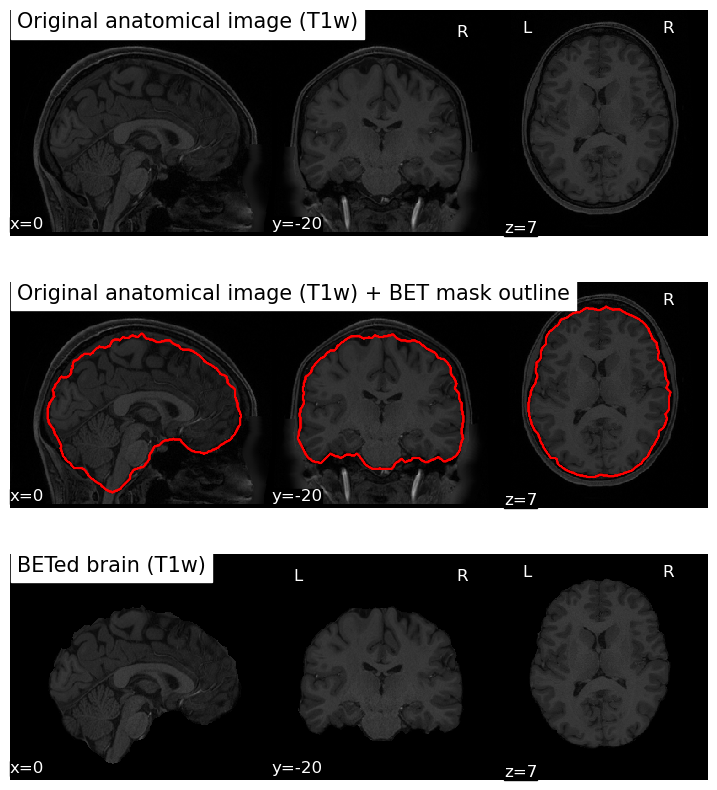

In [3]:
# Plotting results: same slices in every row, so that the rows can be compared
CUT = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

# subplot 1: original T1w
plotting.plot_anat(t1_path, axes=axs[0], cut_coords=CUT, draw_cross=False,
                   title="Original anatomical image (T1w)", colorbar=False)

# subplot 2: original T1w with the brain mask outline in red (to check the extraction quality)
ax = plotting.plot_anat(t1_path, axes=axs[1], cut_coords=CUT, draw_cross=False,
                        title="Original anatomical image (T1w) + BET mask outline", colorbar=False)
ax.add_contours(mask, colors="r", linewidths=1)  # draw the mask boundary

# subplot 3: betted brain
plotting.plot_anat(brain, axes=axs[2], cut_coords=CUT, draw_cross=False,
                   title="BETed brain (T1w)", colorbar=False)

fig.savefig(op.join(fig_dir, "1_skull_stripping_BET.png"), dpi=FIG_DPI)
plt.show()

### Annex: choice of the BET threshold `-f`

The same BET run with the default `-f 0.5`, to justify the choice of 0.3. Both outlines are drawn on a low slice, where the two masks differ most.

Brain mask volume  -f 0.3: 1379 mL   -f 0.5: 1322 mL


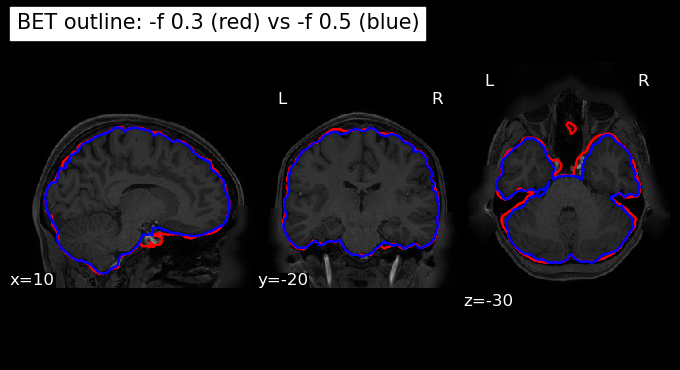

In [4]:
bet05_prefix = op.join(out_anatomical_dir, "T1w_brain_f05")
mask05 = bet05_prefix + "_mask.nii.gz"
subprocess.run(["bet", t1_path, bet05_prefix, "-R", "-f", "0.5", "-m"], check=True)

def volume_ml(img_path):
    """Volume (mL) of the non-zero voxels of an image."""
    img = nib.load(img_path)
    return (img.get_fdata() > 0).sum() * np.prod(img.header.get_zooms()[:3]) / 1000

print(f"Brain mask volume  -f 0.3: {volume_ml(mask):.0f} mL   -f 0.5: {volume_ml(mask05):.0f} mL")

d = plotting.plot_anat(t1_path, cut_coords=(10, -20, -30), draw_cross=False, colorbar=False,
                       title="BET outline: -f 0.3 (red) vs -f 0.5 (blue)")
d.add_contours(mask, colors="r", linewidths=1)
d.add_contours(mask05, colors="b", linewidths=1)
d.savefig(op.join(fig_dir, "annex_BET_threshold.png"), dpi=FIG_DPI)
plt.show()

## 2. tissue segmentation with FSL FAST

**Purpose.** Separate grey matter, white matter and CSF. This checks the anatomy, gives a grey-matter mask that restricts the fMRI analysis to where the BOLD signal comes from, and gives WM/CSF masks for nuisance regressors.

The tissue volumes printed below give a quantitative check of the segmentation, on top of the visual one.

In [ ]:
# Run FAST (takes a few minutes)
fast_prefix = op.join(out_anatomical_dir, "T1w_brain_fast")
seg = fast_prefix + "_seg.nii.gz"       # hard labels: 1 = CSF, 2 = GM, 3 = WM

# FAST: -t 1 = T1 image, -n 3 = three tissue classes
subprocess.run(["fast", "-t", "1", "-n", "3", "-o", fast_prefix, brain], check=True)

# Tissue volumes from the partial-volume maps (pve_k = fraction of tissue k in each voxel)
voxel_ml = np.prod(nib.load(brain).header.get_zooms()[:3]) / 1000
for k, name in enumerate(["CSF", "Grey matter", "White matter"]):
    pve = nib.load(f"{fast_prefix}_pve_{k}.nii.gz").get_fdata()
    print(f"{name:13s}: {pve.sum() * voxel_ml:4.0f} mL")

In [ ]:
# Plotting the segmentation results
# x = -30: a lateral sagittal slice shows the cortical ribbon (x = 0 falls in the interhemispheric fissure)
fig = plt.figure(figsize=(9, 4))

plotting.plot_roi(seg, bg_img=brain, cut_coords=(-30, -20, 7), vmin=1, vmax=3,
                  cmap=ListedColormap(["darkblue", "red", "yellow"]),
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")



fig.legend(handles=[Patch(color="darkblue", label="CSF"),
                    Patch(color="red", label="Grey matter"),
                    Patch(color="yellow", label="White matter")],
           loc="lower center", ncol=3)

fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=FIG_DPI)
plt.show()

## 3. registration to MNI space

**Purpose.** Bring the subject into a standard space. Activations can then be read with the coordinates and atlases of the literature (GLM questions 3e-f). The anatomy is also put into the space of the fMRI, which HCP provides already registered to MNI (*MNINonLinear*).

1. **FLIRT, linear, 12 DOF.** The matrix has scale factors of ~1.08 / 1.12 / 1.18 (the subject's brain is smaller than the template). A rigid 6-DOF transform could not absorb them, hence the 12-DOF affine.
2. **ANTs SyN, non-linear (as in lab 2).** The HCP fMRI was normalised non-linearly, so the T1 must be too. Otherwise the residual mismatches (ventricles, sulci) would come from the T1, and the anat-func overlay of step 2c would look misaligned. SyN takes a few seconds and clearly improves the match with the template (Dice and correlation printed below).

The SyN transform is also applied to the FAST segmentation (nearest neighbour, to keep integer labels). It gives the grey-matter mask in MNI space for the GLM.

Note: the native T1 is already AC-PC aligned by the HCP pipeline, with an origin close to MNI. This is why the "before" panel is already roughly centred.

In [ ]:
affine_mat = op.join(out_anatomical_dir, "T1_to_MNI_flirt.mat") # linear transformation matrix (from FLIRT)
brain_flirt = op.join(out_anatomical_dir, "T1w_brain_MNI_FLIRT.nii.gz")

# FLIRT: linear registration (defaults written explicitly: 12 DOF affine, correlation ratio cost)
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt, "-omat", affine_mat,
                "-dof", "12", "-cost", "corratio"], check=True)
print("FLIRT matrix:\n", np.loadtxt(affine_mat).round(3))


# ANTs SyN: non-linear registration (lab 2), initialised by an affine step inside ants.registration
import ants
brain_syn = op.join(out_anatomical_dir, "T1w_brain_MNI_SyN.nii.gz")
seg_mni = op.join(out_anatomical_dir, "T1w_brain_fast_seg_MNI_SyN.nii.gz")

mni_ants = ants.image_read(mni_brain)
tx = ants.registration(fixed=mni_ants, moving=ants.image_read(brain), type_of_transform="SyN")
ants.image_write(tx["warpedmovout"], brain_syn)

# same transform applied to the tissue labels (nearest neighbour keeps the labels 1/2/3)
seg_warped = ants.apply_transforms(fixed=mni_ants, moving=ants.image_read(seg),
                                   transformlist=tx["fwdtransforms"], interpolator="nearestNeighbor")
ants.image_write(seg_warped, seg_mni)


def match_with_mni(img_path):
    """Intensity correlation and Dice of the brain masks between an image and the MNI brain template."""
    x = nib.load(img_path).get_fdata()
    m = nib.load(mni_brain).get_fdata()
    union = (x > 0) | (m > 0)
    corr = np.corrcoef(x[union], m[union])[0, 1]
    dice = 2 * ((x > 0) & (m > 0)).sum() / ((x > 0).sum() + (m > 0).sum())
    return corr, dice

reg_scores = {name: match_with_mni(p) for name, p in [("FLIRT", brain_flirt), ("SyN", brain_syn)]}
for name, (corr, dice) in reg_scores.items():
    print(f"{name:5s}: correlation with MNI = {corr:.3f}   Dice = {dice:.3f}")

In [ ]:
# Plotting pre- and post-registration results, same slices in every panel
CUT_MNI = (0, -15, 5)
fig, axs = plt.subplots(3, 1, figsize=(9, 14))

d = plotting.plot_anat(brain, axes=axs[0], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r") # MNI edges on top

corr, dice = reg_scores["FLIRT"]
d = plotting.plot_anat(brain_flirt, axes=axs[1], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER linear registration (FLIRT)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")

corr, dice = reg_scores["SyN"]
d = plotting.plot_anat(brain_syn, axes=axs[2], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER non-linear registration (ANTs SyN)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")


fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=FIG_DPI)
plt.show()

# Functional preprocessing (Part 1, practical 2)

The anatomy is skull-stripped, segmented and registered to MNI (`T1w_brain_MNI_SyN.nii.gz`, `T1w_brain_fast_seg_MNI_SyN.nii.gz`). The fMRI run is now prepared for the GLM:

| section | step | tool | output (in `derivatives/func`) | figure |
|---|---|---|---|---|
| 4.1 | loading and checking the run | `fslinfo`, nibabel | - | - |
| 4.2 | problematic volumes: looking at the data | `fslstats -t` | - | `4a_global_signal.png` |
| 4.3 | field stabilization (non-stationary volumes) | `fslroi` | `func_trimmed.nii.gz` (if needed), `task_onsets_used.csv` | - |
| 4.4 | motion correction | `mcflirt` | `func_mc.nii.gz`, `func_mc.par` | - |
| 4.5 | framewise displacement | numpy | `fd.txt` | `4b_motion_FD.png` |
| 4.6 | irregular volume handling | numpy | `motion_confounds.txt` | - |
| 5.1 | functional brain mask | `fslmaths -Tmean`, `bet` | `func_mean_brain_mask.nii.gz` | - |
| 5.2 | Gaussian smoothing | `fslmaths -s` | `func_mc_brain_smooth6mm.nii.gz` | `5_smoothing.png` |
| 6 | validation of the anat-func alignment | nilearn | - | `6_func_anat_alignment.png` |

Why this order: the non-stationary volumes are removed before motion correction, because their higher contrast would bias the MCFLIRT reference (the mean volume) and the realignment cost. Motion correction comes before smoothing, otherwise we would smooth volumes that are not yet aligned.

## 4. motion correction with FSL MCFLIRT

**Purpose.** Make sure that head motion and scanner effects do not drive the GLM. We follow the order of the lab: look at the data, remove the non-stationary volumes, then realign. The non-stationary volumes go first because their brighter contrast would bias the MCFLIRT reference, which is the mean volume.

1. **Looking at the data.** The header confirms what we expect from the HCP *MNINonLinear* version: 2 mm voxels on the MNI grid, TR = 0.72 s. The onsets file goes on a few seconds after the last volume, so the last math block is cut short by the end of the scan. In the GLM these events are simply truncated. The global signal (mean of the brain voxels in each volume, `fslstats -t -M`) is plotted with the story and math blocks in figure 4a.
2. **Field stabilization.** Figure 4a shows a short transient: the first volume is brighter, and the signal is back to baseline within a few volumes. It is much smaller than in the lab dataset, because HCP acquires dummy scans that are discarded before the data are saved. Following the lab, we remove the first volumes with `fslroi`, keeping a small margin after the transient. Removing 10 volumes as in the lab would cost 7.2 s at TR = 0.72 s and cut into the first story block. Every onset is shifted by N × TR, and the shifted onsets (`task_onsets_used.csv`) are the ones used in the GLM.
3. **Motion correction.** MCFLIRT realigns each volume to the mean volume with a rigid-body transform (`-dof 6`: 3 translations and 3 rotations, since the brain does not change shape between volumes). In figure 4b the estimated motion stays far below a voxel, and the translations jump back and forth between two values instead of drifting smoothly. Real head motion does not look like this: it is estimation noise from MCFLIRT, which has almost nothing left to correct because HCP already realigned the run.
4. **Framewise displacement** (Power et al., 2012). $FD_t = |\Delta t_x| + |\Delta t_y| + |\Delta t_z| + 50\,(|\Delta r_x| + |\Delta r_y| + |\Delta r_z|)$, with the rotations converted to mm on a 50 mm sphere. We use an absolute threshold of 0.5 mm. The boxplot rule of the lab (Q3 + 1.5 IQR) is printed for comparison. It is relative to the run, so it flags volumes even here, where every volume moves much less than a voxel. No volume reaches 0.5 mm, and the FD peaks come from the jumps described above.
5. **Irregular volumes.** If a volume were flagged, it would not be deleted: removing volumes in the middle of the run breaks the regular sampling needed for the HRF convolution and for Part 2. It would get a spike regressor (1 at that volume, 0 elsewhere) instead. These regressors are saved with the 6 motion parameters in `motion_confounds.txt` for the GLM.

> **To decide as a group (review part1-func).** Number of non-stationary volumes to remove (`N_DISCARD`). The transient is over after a few volumes, so the default is 3 (about 2 s), which keeps a margin as in the lab. 10 volumes would also be defensible but costs part of the first story block.

In [ ]:
import pandas as pd
from nilearn import image

func_dir = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR")
func_path = op.join(func_dir, "tfMRI_LANGUAGE_LR.nii.gz")              # original fMRI run (4D)
events_path = op.join(func_dir, "tfMRI_LANGUAGE_LR_task_onsets.csv")   # task timing
out_func_dir = op.join(out_dir, "func")
os.makedirs(out_func_dir, exist_ok=True)
mni_brain_2mm = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # template at the fMRI resolution

assert op.exists(func_path), f"fMRI run not found: {func_path}"
assert op.exists(events_path), f"Onsets file not found: {events_path}"
assert shutil.which("mcflirt"), "FSL mcflirt not found in the PATH"

# Header check: voxel size, TR and grid are used by all the next steps
func_img = nib.load(func_path)
n_vols_raw = func_img.shape[3]
voxel_size = func_img.header.get_zooms()[:3]
TR = float(func_img.header.get_zooms()[3])                             # repetition time (s)
print(f"{n_vols_raw} volumes, voxel size {voxel_size} mm, TR = {TR} s, "
      f"on the MNI 2 mm grid: {np.allclose(func_img.affine, nib.load(mni_brain_2mm).affine)}")

events_raw = pd.read_csv(events_path)
last_event_end = (events_raw["onset"] + events_raw["duration"]).max()
print(f"Scan duration: {n_vols_raw * TR:.1f} s   last event ends at: {last_event_end:.1f} s")
if last_event_end > n_vols_raw * TR:
    print("-> the last events go past the end of the scan, they will be truncated in the GLM")

# Global signal: mean of the non-zero (brain) voxels of each volume (-t = one value per volume)
out = subprocess.run(["fslstats", "-t", func_path, "-M"], capture_output=True, text=True, check=True).stdout
global_raw = np.array(out.split(), dtype=float)
baseline = np.median(global_raw[10:])                                   # reference level, after the transient
print("First 10 volumes, % of baseline:", np.round(100 * (global_raw[:10] / baseline - 1), 2))

# Non-stationary volumes: chosen by looking at figure 4a (see the markdown, decided as a group)
N_DISCARD = 3

events = events_raw.copy()
if N_DISCARD > 0:
    func_input = op.join(out_func_dir, "func_trimmed.nii.gz")
    # fslroi: keep volumes N_DISCARD ... end (first volume is 0, not 1!)
    subprocess.run(["fslroi", func_path, func_input, str(N_DISCARD), str(n_vols_raw - N_DISCARD)], check=True)
    events["onset"] -= N_DISCARD * TR                                   # new time origin
    starts_before = events["onset"] < 0                                 # clip what starts before it
    events.loc[starts_before, "duration"] += events.loc[starts_before, "onset"]
    events.loc[starts_before, "onset"] = 0.0
    events = events[events["duration"] > 0].reset_index(drop=True)
else:
    func_input = func_path

n_vols = nib.load(func_input).shape[3]
events.to_csv(op.join(out_func_dir, "task_onsets_used.csv"), index=False)  # onsets to use in the GLM
print(f"Removed {N_DISCARD} volumes ({N_DISCARD * TR:.1f} s), kept {n_vols} volumes")

In [ ]:
# Plotting the global signal of the raw run, with the task blocks and the removed volumes
block_colors = {"story": "tab:green", "math": "tab:orange"}
blocks_raw = events_raw[events_raw["trial_type"].isin(["story", "math"])]

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(n_vols_raw), 100 * (global_raw / baseline - 1), color="k", lw=1)
for _, ev in blocks_raw.iterrows():                                     # task blocks, converted from s to volumes
    ax.axvspan(ev["onset"] / TR, (ev["onset"] + ev["duration"]) / TR,
               color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
if N_DISCARD > 0:
    ax.axvspan(-0.5, N_DISCARD - 0.5, color="r", alpha=0.3, lw=0)       # removed volumes
ax.axvline(n_vols_raw - 0.5, color="k", ls=":", lw=1)                   # end of the scan
ax.set(xlabel="time (volume)", ylabel="mean intensity (% of baseline)",
       title=f"Global signal of the raw run (fslstats -t -M), first {N_DISCARD} volumes removed")
ax.legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                   Patch(color="tab:orange", alpha=0.3, label="math"),
                   Patch(color="r", alpha=0.3, label="removed"),
                   plt.Line2D([], [], color="k", ls=":", label="end of scan")], loc="upper right", ncol=4)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4a_global_signal.png"), dpi=FIG_DPI)
plt.show()

In [ ]:
mc_prefix = op.join(out_func_dir, "func_mc")
func_mc = mc_prefix + ".nii.gz"           # motion-corrected run
par_file = mc_prefix + ".par"             # 6 motion parameters per volume

# 3. MCFLIRT: rigid-body (6 DOF) realignment to the mean volume (takes a few minutes)
subprocess.run(["mcflirt", "-in", func_input, "-out", mc_prefix, "-dof", "6",
                "-meanvol", "-plots", "-rmsabs", "-rmsrel", "-spline_final"], check=True)
motion = np.loadtxt(par_file)             # columns: rx ry rz (rad), tx ty tz (mm)
assert motion.shape[0] == n_vols

# 4. Framewise displacement (Power et al., 2012)
HEAD_RADIUS = 50.0                        # mm, converts rotations (rad) into displacements (mm)
FD_THRESH = 0.5                           # mm, absolute threshold for the irregular volumes
delta = np.abs(np.diff(motion, axis=0))
fd = np.concatenate([[0.0], delta[:, 3:].sum(axis=1) + HEAD_RADIUS * delta[:, :3].sum(axis=1)])  # FD = 0 at the first volume
np.savetxt(op.join(out_func_dir, "fd.txt"), fd, fmt="%.5f")

q1, q3 = np.quantile(fd, [0.25, 0.75])
fd_boxplot = q3 + 1.5 * (q3 - q1)         # threshold of the lab, for comparison
outliers = np.where(fd > FD_THRESH)[0]
print(f"FD: mean = {fd.mean():.3f} mm, median = {np.median(fd):.3f} mm, max = {fd.max():.3f} mm")
print(f"Volumes with FD > {FD_THRESH} mm: {len(outliers)} / {n_vols}  {outliers.tolist()}")
print(f"(boxplot threshold Q3 + 1.5 IQR = {fd_boxplot:.3f} mm would flag {(fd > fd_boxplot).sum()} volumes)")

# 5. Irregular volumes: one spike regressor per flagged volume, saved with the 6 motion parameters for the GLM
spikes = np.zeros((n_vols, len(outliers)))
spikes[outliers, np.arange(len(outliers))] = 1
confounds = np.column_stack([motion, spikes])
np.savetxt(op.join(out_func_dir, "motion_confounds.txt"), confounds, fmt="%.6f")
print(f"Confound matrix: {confounds.shape}  (6 motion parameters + {len(outliers)} spike regressors)")

In [ ]:
# Plotting the motion parameters and the FD, with the task blocks in the background
t = np.arange(n_vols) * TR
blocks = events[events["trial_type"].isin(["story", "math"])]           # onsets after the possible shift

fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axs[0].plot(t, motion[:, 3:], lw=1)
axs[0].set(ylabel="translation (mm)", title="Motion parameters (MCFLIRT)")
axs[0].legend(["x", "y", "z"], loc="upper right", ncol=3)
axs[1].plot(t, np.degrees(motion[:, :3]), lw=1)
axs[1].set(ylabel="rotation (deg)")
axs[1].legend(["pitch (x)", "roll (y)", "yaw (z)"], loc="upper right", ncol=3)
axs[2].plot(t, fd, color="k", lw=1)
axs[2].axhline(FD_THRESH, color="r", ls="--")
axs[2].scatter(t[outliers], fd[outliers], color="r", zorder=3)
axs[2].set(ylabel="FD (mm)", xlabel="time (s)",
           title=f"Framewise displacement (mean {fd.mean():.3f} mm, {len(outliers)} volume(s) > {FD_THRESH} mm)")

for ax in axs:                                                          # shade the story/math blocks
    for _, ev in blocks.iterrows():
        ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
axs[2].legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                       Patch(color="tab:orange", alpha=0.3, label="math"),
                       plt.Line2D([], [], color="r", ls="--", label=f"FD = {FD_THRESH} mm")],
              loc="upper right", ncol=3)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4b_motion_FD.png"), dpi=FIG_DPI)
plt.show()

In [ ]:
# Effect of motion correction: DVARS and carpet plots before vs after MCFLIRT, aligned with the FD
mni_mask_2mm = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain_mask.nii.gz")  # same grid as the fMRI
brain_vox = nib.load(mni_mask_2mm).get_fdata() > 0

def dvars_pct(img_path):
    """DVARS (Power et al., 2012): RMS over voxels of the volume-to-volume signal change, in % of the mean signal."""
    data = nib.load(img_path).get_fdata(dtype=np.float32)[brain_vox]   # voxels x time
    dv = np.sqrt(np.mean(np.diff(data, axis=1) ** 2, axis=0)) / data.mean() * 100
    return np.concatenate([[0.0], dv])                                  # DVARS = 0 at the first volume

dvars_before, dvars_after = dvars_pct(func_input), dvars_pct(func_mc)
print(f"Mean DVARS  before MC: {dvars_before.mean():.3f} %   after MC: {dvars_after.mean():.3f} %")

fig = plt.figure(figsize=(9, 12))
gs = fig.add_gridspec(4, 1, height_ratios=[1, 1, 2.5, 2.5], hspace=0.45)

ax = fig.add_subplot(gs[0])
ax.plot(np.arange(n_vols), fd, color="k", lw=1)
ax.axhline(FD_THRESH, color="r", ls="--")
ax.set(ylabel="FD (mm)", xlim=(0, n_vols - 1), title="Framewise displacement")

ax = fig.add_subplot(gs[1])
ax.plot(np.arange(n_vols), dvars_before, color="tab:red", lw=1, label="before MC")
ax.plot(np.arange(n_vols), dvars_after, color="tab:blue", lw=1, label="after MC")
ax.set(ylabel="DVARS (%)", xlim=(0, n_vols - 1), title="DVARS before vs after motion correction")
ax.legend(loc="upper right", ncol=2)

# Carpet plot: one row per brain voxel (detrended, z-scored), one column per volume.
# Motion would appear as vertical stripes across many voxels at the same time.
plotting.plot_carpet(func_input, mask_img=mni_mask_2mm, axes=fig.add_subplot(gs[2]),
                     title="Carpet plot BEFORE motion correction")
plotting.plot_carpet(func_mc, mask_img=mni_mask_2mm, axes=fig.add_subplot(gs[3]),
                     title="Carpet plot AFTER motion correction (MCFLIRT)")

fig.savefig(op.join(fig_dir, "4c_motion_correction_effect.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 5. Gaussian smoothing with FSL

**Purpose.** Averaging neighbouring voxels with a 3D Gaussian reduces the noise, which is mostly independent from voxel to voxel, while keeping the activations, which extend over several voxels. It also brings the data closer to the assumptions of the voxel-wise statistics (Gaussian random fields). The price is spatial specificity: small activations get diluted, and grey-matter signal spreads into WM and CSF. Figure 5 shows the trade-off: the volume loses its fine detail, and the temporal SNR goes up by a large factor.

**Parameters.** FWHM = 6 mm, 3 times the 2 mm voxel size. The language and math regions are several mm to a few cm wide, and 8 mm is usually kept for group studies. FSL takes a sigma, not a FWHM: σ = FWHM / (2√(2 ln 2)) ≈ 2.55 mm.

The smoothing is done inside a brain mask (BET `-f 0.3` on the mean of the motion-corrected run, as for the T1). The smoothed data are divided by the smoothed mask, so the edges of the brain are not darkened by the zeros outside it. The first row of figure 5 checks that the mask follows the brain. The tSNR gain overstates the real gain in detection power, because smoothing also makes the noise of neighbouring voxels correlated.

Not applied: slice-timing correction (multiband, TR = 0.72 s, so the timing differences between slices are small compared with the HRF and the ~30 s blocks; HCP does not apply it either) and high-pass filtering (the slow drifts visible in figure 4a are modelled in the GLM with cosine regressors instead).

> **To decide as a group (review part1-func).** FWHM: 6 mm (default) or 4 mm, which keeps more spatial detail and is one of the levels HCP uses for its own task maps.

In [ ]:
# Functional brain mask: BET on the temporal mean of the motion-corrected run
mean_func = op.join(out_func_dir, "func_mc_mean.nii.gz")          # temporal mean (3D)
func_brain_prefix = op.join(out_func_dir, "func_mean_brain")
func_mask = func_brain_prefix + "_mask.nii.gz"                     # functional brain mask
func_mc_brain = op.join(out_func_dir, "func_mc_brain.nii.gz")      # masked motion-corrected run

subprocess.run(["fslmaths", func_mc, "-Tmean", mean_func], check=True)
subprocess.run(["bet", mean_func, func_brain_prefix, "-f", "0.3", "-m"], check=True)
subprocess.run(["fslmaths", func_mc, "-mas", func_mask, func_mc_brain], check=True)
print(f"Functional mask volume: {volume_ml(func_mask):.0f} mL   (T1 BET mask: {volume_ml(mask):.0f} mL)")

# Gaussian smoothing inside the mask: smooth(data) / smooth(mask), then re-mask
FWHM = 6.0                                                         # mm (decided as a group)
sigma = FWHM / (2 * np.sqrt(2 * np.log(2)))                        # FSL uses sigma, not FWHM
func_smooth = op.join(out_func_dir, f"func_mc_brain_smooth{FWHM:.0f}mm.nii.gz")
tmp_num = op.join(out_func_dir, "tmp_smooth_data.nii.gz")
tmp_den = op.join(out_func_dir, "tmp_smooth_mask.nii.gz")

subprocess.run(["fslmaths", func_mc_brain, "-s", f"{sigma:.4f}", tmp_num], check=True)
subprocess.run(["fslmaths", func_mask, "-s", f"{sigma:.4f}", tmp_den], check=True)
subprocess.run(["fslmaths", tmp_num, "-div", tmp_den, "-mas", func_mask, func_smooth, "-odt", "float"], check=True)
os.remove(tmp_num); os.remove(tmp_den)
print(f"FWHM = {FWHM} mm  ->  sigma = {sigma:.3f} mm")

def median_tsnr(img_4d, mask_path):
    """Median temporal SNR (mean / std over time) in the mask, computed with fslmaths."""
    m, s, r = (op.join(out_func_dir, f"tmp_{k}.nii.gz") for k in ("mean", "std", "tsnr"))
    subprocess.run(["fslmaths", img_4d, "-Tmean", m], check=True)
    subprocess.run(["fslmaths", img_4d, "-Tstd", s], check=True)
    subprocess.run(["fslmaths", m, "-div", s, "-mas", mask_path, r], check=True)
    vals = nib.load(r).get_fdata()[nib.load(mask_path).get_fdata() > 0]
    for f in (m, s, r): os.remove(f)
    return np.median(vals)

tsnr_before, tsnr_after = median_tsnr(func_mc_brain, func_mask), median_tsnr(func_smooth, func_mask)
print(f"Median tSNR  before smoothing: {tsnr_before:.1f}   after: {tsnr_after:.1f}")

In [ ]:
# Plotting the functional mask, then one volume before and after smoothing (same slices, same intensity scale)
VOL = n_vols // 2                                    # volume of our choice: the middle of the run
vol_before = op.join(out_func_dir, f"vol{VOL}_before_smoothing.nii.gz")
vol_after = op.join(out_func_dir, f"vol{VOL}_after_smoothing.nii.gz")
subprocess.run(["fslroi", func_mc_brain, vol_before, str(VOL), "1"], check=True)   # extract 1 volume
subprocess.run(["fslroi", func_smooth, vol_after, str(VOL), "1"], check=True)

data_before = nib.load(vol_before).get_fdata()
vmax = np.percentile(data_before[data_before > 0], 99)  # common scale for both volumes

CUT_FUNC = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

d = plotting.plot_epi(mean_func, axes=axs[0], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False, cmap="gray",
                      title="Mean fMRI + functional brain mask outline (BET)")
d.add_contours(func_mask, colors="r", linewidths=1)

plotting.plot_epi(vol_before, axes=axs[1], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax, title=f"fMRI volume {VOL}, BEFORE smoothing (tSNR = {tsnr_before:.1f})")

plotting.plot_epi(vol_after, axes=axs[2], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax,
                  title=f"fMRI volume {VOL}, AFTER smoothing, FWHM = {FWHM:.0f} mm (tSNR = {tsnr_after:.1f})")

fig.savefig(op.join(fig_dir, "5_smoothing.png"), dpi=FIG_DPI)
plt.show()

## 6. validation of the anatomical-functional alignment

**Purpose.** The GLM maps are shown on the T1 and read with MNI atlases, so the fMRI and the T1 must overlap voxel to voxel. Figure 6 checks it in both directions, on lateral slices through the ventricles and the insula (x = 0 falls in the interhemispheric fissure):
- top, the edges of the T1 drawn over one fMRI volume. The edges are computed on the T1, because edge detection on the noisy EPI finds edges everywhere inside the brain;
- bottom, the outline of the fMRI brain drawn over the T1.

The T1 edges follow the ventricles, the insula and the cortical folding of the fMRI, and the fMRI outline follows the T1 brain except at the base of the brain (inferior temporal lobes, cerebellum). There the EPI loses signal near the sinuses and ear canals, and the T1 mask from BET `-f 0.3` also keeps some CSF. The Dice between the brain masks only tests the outer boundary. To test the inside of the brain, we let FLIRT register the mean fMRI onto the T1 (rigid, starting from the current position) and measure how much it would move the data. The residual displacement is about half a voxel, which is close to the accuracy of an EPI-to-T1 registration itself.

> **Which step can be avoided?** The coregistration of the fMRI to the T1 and its normalisation to MNI (`epi_reg`/BBR + `applywarp`). The HCP fMRI is already non-linearly normalised to MNI: it is on the MNI 2 mm grid (section 4), its internal structures line up with the SyN-registered T1, and the remaining misalignment is below one voxel. Registering it again could gain at most about half a voxel, but it would add an interpolation that blurs the data. This is also why the T1 needed SyN and not only FLIRT: a T1 aligned only linearly would not match the fMRI at the ventricles and sulci.

In [ ]:
# Dice between the functional mask (resampled to 1 mm) and the T1 brain mask in MNI (outer boundary only)
func_mask_1mm = image.resample_to_img(func_mask, brain_syn, interpolation="nearest").get_fdata() > 0
t1_mask_mni = nib.load(brain_syn).get_fdata() > 0
dice_func_t1 = 2 * (func_mask_1mm & t1_mask_mni).sum() / (func_mask_1mm.sum() + t1_mask_mni.sum())

# Residual misalignment: rigid FLIRT of the mean fMRI onto the T1 in MNI, starting from the current position.
# If the data are aligned, FLIRT finds (almost) the identity: the RMS displacement it would apply is ~0 mm.
resid_mat = op.join(out_func_dir, "func_to_T1MNI_residual.mat")
ident_mat = op.join(out_func_dir, "identity.mat")
np.savetxt(ident_mat, np.eye(4), fmt="%.1f")
subprocess.run(["flirt", "-in", mean_func, "-ref", brain_syn, "-omat", resid_mat,
                "-dof", "6", "-cost", "normmi", "-nosearch"], check=True)   # normmi: different contrasts (EPI vs T1)
rms_resid = float(subprocess.run(["rmsdiff", ident_mat, resid_mat, brain_syn],
                                 capture_output=True, text=True, check=True).stdout.split()[0])
print(f"Dice (functional vs T1 brain mask): {dice_func_t1:.3f}")
print(f"Residual misalignment found by FLIRT (RMS displacement): {rms_resid:.2f} mm  (voxel size {voxel_size[0]:.0f} mm)")

# Plotting: T1 edges over the fMRI, and the fMRI brain outline over the T1
CUT_ALIGN = (-30, -15, 15)                           # lateral slices through the ventricles and the insula
fig, axs = plt.subplots(2, 1, figsize=(9, 7))

d = plotting.plot_epi(vol_before, axes=axs[0], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False, cmap="gray",
                      title=f"fMRI volume {VOL} + edges of the T1 in MNI (red)")
d.add_edges(brain_syn, color="r")

d = plotting.plot_anat(brain_syn, axes=axs[1], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False,
                       title=f"T1 in MNI + outline of the fMRI brain (red)  Dice={dice_func_t1:.3f}, "
                             f"residual={rms_resid:.2f} mm")
d.add_contours(func_mask, levels=[0.5], colors="r", linewidths=1)

fig.savefig(op.join(fig_dir, "6_func_anat_alignment.png"), dpi=FIG_DPI)
plt.show()